# Energy vs. iteration — VMC sweep viewer

Loads NetKet `JsonLog` output from one or more sweep folders produced by `submit.sh`
and plots **energy vs. iteration**.

**How the data is laid out** (from `run_2D_eigenbasis.py`):
- Each sweep folder you paste (e.g. `2026-08-31_18-49-59G5f5e260P1851807`) contains
  one subfolder per swept parameter combination: `run_0000/`, `run_0001/`, ...
- Inside each `run_XXXX/`, the energy history is a NetKet log with prefix `run`,
  i.e. `run.log` (JSON).
- **Resumed runs** write extra logs like `run step 3000.log`. Their iteration
  numbers are *global*, so this notebook globs **every** `*.log` in a run dir and
  merges them by iteration to reconstruct the full curve.

**Reference energies.** For small systems the script stores the ED ground state in
`run.summary.json` (`E0`, total). For large systems (e.g. 6x6) ED is skipped, so
you can supply a known **per-site** reference in `E0_PER_SITE_REF` below, keyed by
`(L, J2)`.

Just edit the config cell and run all.

In [75]:
from pathlib import Path

# --- EDIT ME ---------------------------------------------------------------
# Base directory holding your sweep folders (this is RUN_ROOT in submit.sh).
# Resolved relative to this notebook so the same config works on the RC cluster
# and locally: "data/eigenbasis" lives in the repo root above the folder holding this
# notebook. Notebooks have no __file__, but Path.cwd() is the notebook's dir;
# we walk up a few levels in case the kernel was started from the repo root.
def _find_data_root(name="data/eigenbasis"):
    here = Path.cwd().resolve()
    for base in (here, *here.parents):
        cand = base / name
        if cand.is_dir():
            return cand
    raise FileNotFoundError(f"could not find a {name!r} directory at or above {here}")

DATA_ROOT = _find_data_root()
print("DATA_ROOT =", DATA_ROOT)

# Paste the sweep-folder names you want to plot (one per line).
SWEEP_FOLDERS = [
    # "2026-08-31_18-49-59G5f5e260P1851807",
    # "2026-08-31_18-55-30Gf0a713aP1869257",
    # "2026-09-01_13-38-15G5810413P2340655",
    # "2026-09-02_13-46-40Gab8c5fcP633926"
    # "2026-09-14_15-21-57Gdb5ab70P1131412"
    '2026-09-17_14-07-13Gbcd9a5dP2861577',
    '2026-09-17_18-22-55G86bfd8fP557666'

]
# SWEEP_FOLDERS = ["2026-09-03_12-22-52Gbfdee23P1006266"]


# Optional human-friendly labels for each sweep (parallel to SWEEP_FOLDERS).
# Use an empty string or None to fall back to the automatic label.
SWEEP_LABELS = [
    # "[2,3,20], ds2=1e-3",
    # "[2,3,20], ds2=1e-4",
    # "ADAM_test1",
    # "ADAM_test2"
]
# SWEEP_LABELS = [None]

# Mapping from sweep folder -> label (only includes non-empty labels).
SWEEP_LABELS_MAP = {k: v for k, v in zip(SWEEP_FOLDERS, SWEEP_LABELS) if v}

# Quantity to plot on the y-axis. NetKet logs the energy under "Energy".
QUANTITY = "Energy"

# Plot energy PER SITE (E / n_sites) instead of the total. Runs whose config
# has no L (so n_sites is unknown) are left as totals, with a warning.
PER_SITE = True

# y-limits for the energy plot, in whatever units PER_SITE selects:
#   None -> autoscale;  e.g. (-26, -20) for totals, (-0.70, -0.60) per site.
YLIM = None

# Manual reference energies PER SITE (E0/site), used for runs that have NO ED
# reference in summary.json (large systems where E0 is null). Keyed by (L, J2).
# On the plots this is drawn at E0/site * n_sites and labeled per-site.
E0_PER_SITE_REF = {
    (6, 0.0): -0.678872,    # 6x6, J2 = 0
}
# ---------------------------------------------------------------------------

DATA_ROOT = /Users/ashilcusky/Documents/master/2D_data


In [76]:
import json
import numpy as np
import matplotlib.pyplot as plt

## Loaders

`load_log` reads a single NetKet `.log`; `load_run_energy` merges all logs in a
run directory (handles resubmissions); `load_meta` pulls swept values, status,
git commit, the system `(L, J2)`, and the reference energy `E0` (ED if present,
otherwise the manual per-site value from `E0_PER_SITE_REF`).

`load_run_info` does the same merge for the driver's own `info.*` series
(`alpha`, `snr`, `grad_snr`), which only adaptive-alpha runs have.


In [77]:
def load_log(log_path):
    """One NetKet JsonLog .log -> (iters, mean_real, err_or_None)."""
    with open(log_path) as f:
        data = json.load(f)
    if QUANTITY not in data:
        raise KeyError(f"{QUANTITY!r} not in {log_path.name}; keys={list(data)}")
    block = data[QUANTITY]
    iters = np.asarray(block["iters"], dtype=float)

    def column(name):
        if name not in block or block[name] is None:
            return None
        col = block[name]
        if isinstance(col, dict) and "real" in col:   # complex -> take real part
            return np.asarray(col["real"], dtype=float)
        return np.asarray(col, dtype=float)

    mean = column("Mean")
    err  = column("Sigma")            # NetKet: error of the mean
    if err is None:
        err = column("Error")
    return iters, mean, err


def load_run_energy(run_dir):
    """Merge every *.log in a run dir into one curve, sorted by global iteration.

    Resubmitted runs write 'run.log', 'run step NNNN.log', ... each with global
    iteration numbers, so we concatenate and sort. Duplicate iterations keep the
    last occurrence.
    """
    logs = sorted(run_dir.glob("*.log"))
    if not logs:
        return None
    its, means, errs, have_err = [], [], [], True
    for lp in logs:
        try:
            it, mean, err = load_log(lp)
        except Exception as e:
            print(f"   (skipped {lp.name}: {e})")
            continue
        its.append(it); means.append(mean)
        if err is None:
            have_err = False
        else:
            errs.append(err)
    if not its:
        return None
    it   = np.concatenate(its)
    mean = np.concatenate(means)
    err  = np.concatenate(errs) if (have_err and errs) else None
    order = np.argsort(it, kind="stable")
    it, mean = it[order], mean[order]
    if err is not None:
        err = err[order]
    # de-duplicate iterations (keep last)
    seen = {}
    for pos, itv in enumerate(it):
        seen[float(itv)] = pos
    keep = np.array([seen[k] for k in sorted(seen)])
    it, mean = it[keep], mean[keep]
    if err is not None:
        err = err[keep]
    return it, mean, err


def _match_ref(L, J2):
    """Look up a manual per-site reference for (L, J2), tolerant on J2 float."""
    if L is None or J2 is None:
        return None
    for (Lr, J2r), val in E0_PER_SITE_REF.items():
        if int(Lr) == int(L) and abs(float(J2r) - float(J2)) < 1e-9:
            return float(val)
    return None


# Architecture knobs shown explicitly in every legend, so if they were swept we
# drop them from the generic swept-value bits instead of printing them twice.
_MODEL_KEYS = {"layers", "heads", "ratio", "d_model"}


def load_meta(run_dir):
    """swept values / status / git / (L, J2) / architecture / reference E0."""
    meta = {"label_bits": [], "status": None, "git": None,
            "L": None, "J2": None, "n_sites": None,
            "E0": None, "E0_per_site": None, "E0_source": None,
            "layers": None, "heads": None, "d_model": None, "model_bits": []}

    cfg = None
    man = run_dir / "manifest.json"
    if man.exists():
        m = json.loads(man.read_text())
        meta["status"] = m.get("status")
        meta["git"]    = (m.get("git_commit") or "")[:7]
        for k, v in (m.get("sweep_values") or {}).items():
            short = k.split(".")[-1]
            if short in _MODEL_KEYS:          # already in model_bits below
                continue
            meta["label_bits"].append(f"{short}={v}")
        cfg = m.get("config")
    if cfg is None:
        cj = run_dir / "config.json"
        if cj.exists():
            cfg = json.loads(cj.read_text())

    if cfg and "system" in cfg:
        meta["L"]  = cfg["system"].get("L")
        meta["J2"] = cfg["system"].get("J2")
        if meta["L"] is not None:
            meta["n_sites"] = int(meta["L"]) ** 2

    if cfg and "model" in cfg:
        mc = cfg["model"]
        meta["layers"] = mc.get("layers")
        meta["heads"]  = mc.get("heads")
        # d_model is not stored in the config: run_2D_eigenbasis.py derives it
        # as ratio * heads, so reproduce that here (newer configs may store it).
        dm = mc.get("d_model")
        if dm is None and mc.get("ratio") is not None and meta["heads"] is not None:
            dm = int(mc["ratio"]) * int(meta["heads"])
        meta["d_model"] = dm
        meta["model_bits"] = [f"{name}={val}" for name, val in
                              (("nlayers", meta["layers"]),
                               ("nheads",  meta["heads"]),
                               ("dmodel",  meta["d_model"])) if val is not None]

    # 1) ED reference (total energy) from summary.json, if present
    summ = run_dir / "run.summary.json"
    if summ.exists():
        try:
            s = json.loads(summ.read_text())
            if s.get("E0") is not None:
                meta["E0"] = float(s["E0"])
                meta["E0_source"] = "ED"
                if meta["n_sites"]:
                    meta["E0_per_site"] = meta["E0"] / meta["n_sites"]
        except Exception:
            pass

    # 2) otherwise, manual per-site reference for matching (L, J2)
    if meta["E0"] is None:
        ref = _match_ref(meta["L"], meta["J2"])
        if ref is not None:
            meta["E0_per_site"] = ref
            meta["E0_source"]   = "ref"
            if meta["n_sites"]:
                meta["E0"] = ref * meta["n_sites"]
    return meta


def run_label(r, include_git=True):
    """Legend text: sweep - architecture - other swept values - git commit."""
    parts = [SWEEP_LABELS_MAP.get(r["sweep"]) or r["sweep"][:19]]
    if r["model_bits"]:
        parts.append(" ".join(r["model_bits"]))
    parts.append(" ".join(r["label_bits"] or [r["run_dir"].name]))
    if include_git and r["git"]:
        parts.append(r["git"])
    return " · ".join(parts)


def load_run_info(run_dir, key):
    """Merge one driver `info.<key>` series across every *.log in a run dir.

    Adaptive-alpha runs (auto_alpha = true) have VMC_NG log its own state under
    info: 'alpha' (the overdispersion exponent), 'snr', 'grad_snr'. Each is
    {"iters": [...], "value": [...]}. Resubmissions write extra logs whose
    iteration numbers are already GLOBAL, so this concatenates and sorts exactly
    like load_run_energy.

    Returns (iters, values), or None for a run with no info block at all --
    fixed-alpha runs, and anything from before adaptive importance sampling.
    """
    its, vals = [], []
    for lp in sorted(run_dir.glob("*.log")):
        with open(lp) as f:
            data = json.load(f)
        block = data.get("info", {}).get(key)
        if block is None:
            continue
        its.append(np.asarray(block["iters"], dtype=float))
        vals.append(np.asarray(block["value"], dtype=float))
    if not its:
        return None
    it, val = np.concatenate(its), np.concatenate(vals)
    order = np.argsort(it, kind="stable")
    it, val = it[order], val[order]
    _, keep = np.unique(it[::-1], return_index=True)     # de-duplicate, keep last
    keep = len(it) - 1 - keep
    return it[keep], val[keep]


## Load everything

In [78]:
runs = []
for folder in SWEEP_FOLDERS:
    sweep_dir = DATA_ROOT / folder
    if not sweep_dir.exists():
        print(f"!! missing sweep folder: {sweep_dir}")
        continue
    run_dirs = sorted(sweep_dir.glob("run_*"))
    if not run_dirs:
        print(f"!! no run_* subfolders under {sweep_dir}")
    for run_dir in run_dirs:
        loaded = load_run_energy(run_dir)
        if loaded is None:
            print(f"!! no *.log in {run_dir}")
            continue
        it, mean, err = loaded
        meta = load_meta(run_dir)
        runs.append({"sweep": folder, "run_dir": run_dir,
                     "iters": it, "mean": mean, "err": err, **meta})
        e0note = ""
        if meta["E0"] is not None:
            e0note = (f", E0={meta['E0']:.4f} "
                      f"(E0/site={meta['E0_per_site']:.6f}, {meta['E0_source']})")
        arch = " ".join(meta["model_bits"])
        print(f"loaded {folder[:19]}/{run_dir.name}  "
              f"[L={meta['L']} J2={meta['J2']}]  "
              f"{arch}  "
              f"({len(it)} iters, status={meta['status']}, "
              f"{' '.join(meta['label_bits']) or 'base'}{e0note})")

print(f"Total curves: {len(runs)}")

loaded 2026-09-17_14-07-13/run_0000  [L=6 J2=0.0]  nlayers=8 nheads=12 dmodel=72  (9992 iters, status=completed, base, E0=-24.4394 (E0/site=-0.678872, ref))
loaded 2026-09-17_18-22-55/run_0000  [L=6 J2=0.0]  nlayers=2 nheads=12 dmodel=72  (9998 iters, status=completed, base, E0=-24.4394 (E0/site=-0.678872, ref))
Total curves: 2


## Energy vs. iteration

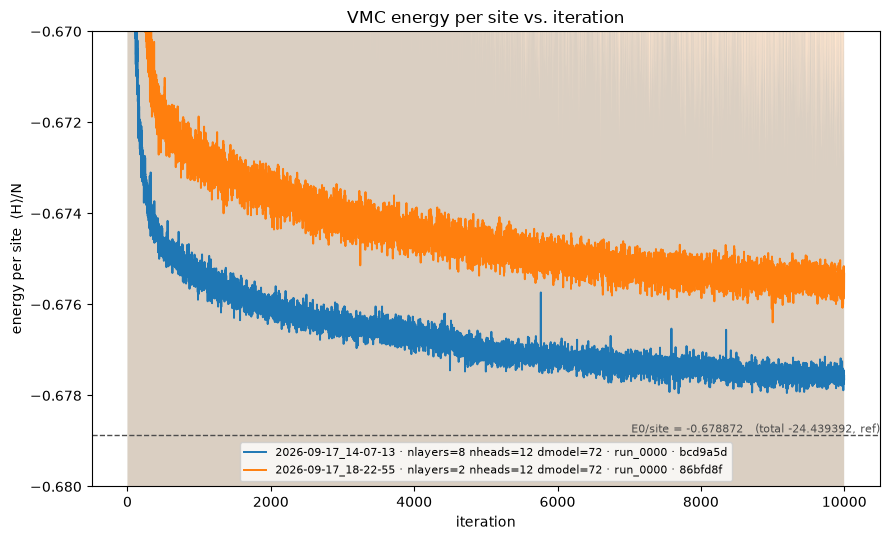

In [91]:
fig, ax = plt.subplots(figsize=(9, 5.5))

PER_SITE = True
if PER_SITE:
    n_missing = sum(1 for r in runs if not r["n_sites"])
    if n_missing:
        print(f"!! {n_missing} run(s) have no L in their config — plotted as totals")

for r in runs:
    n_sites = r["n_sites"] if (PER_SITE and r["n_sites"]) else 1
    y   = r["mean"] / n_sites
    err = r["err"] / n_sites if r["err"] is not None else None
    line, = ax.plot(r["iters"], y, lw=1.4, label=run_label(r))
    if err is not None:
        ax.fill_between(r["iters"], y - err, y + err,
                        color=line.get_color(), alpha=0.20, linewidth=0)

# reference line(s), in the units being plotted; dedupe on that value
refs = {}
for r in runs:
    e0 = r["E0_per_site"] if (PER_SITE and r["n_sites"]) else r["E0"]
    if e0 is not None:
        refs[round(e0, 8)] = (r["E0"], r["E0_per_site"], r["E0_source"])
for e0, (tot, per_site, src) in sorted(refs.items()):
    ax.axhline(e0, ls="--", color="0.3", lw=1)
    tag = "ref" if src == "ref" else "ED"
    if PER_SITE and per_site is not None:
        txt = f"E0/site = {per_site:.6f}   (total {tot:.6f}, {tag})"
    else:
        txt = f"E0 = {tot:.6f}"
        if per_site is not None:
            txt += f"   (E0/site = {per_site:.6f}, {tag})"
    ax.annotate(txt, xy=(1.0, e0), xycoords=("axes fraction", "data"),
                ha="right", va="bottom", fontsize=8, color="0.3")

ax.set_xlabel("iteration")
ax.set_ylabel("energy per site  ⟨H⟩/N" if PER_SITE else "energy  ⟨H⟩")
# if YLIM is not None:
#     ax.set_ylim(*YLIM)
if PER_SITE:
    ax.set_ylim(-0.68, -0.67)
else:
    ax.set_ylim(-24.6, -24)

ax.set_title("VMC energy per site vs. iteration" if PER_SITE
             else "VMC energy vs. iteration")
ax.legend(fontsize=8, loc="best")
fig.tight_layout()
plt.show()


## Relative error vs. iteration (log scale)

For runs that have a reference `E0` (ED or the manual per-site value). Plots
`|E - E0| / |E0|`, which is scale-invariant, so total vs. per-site gives the
same curve.

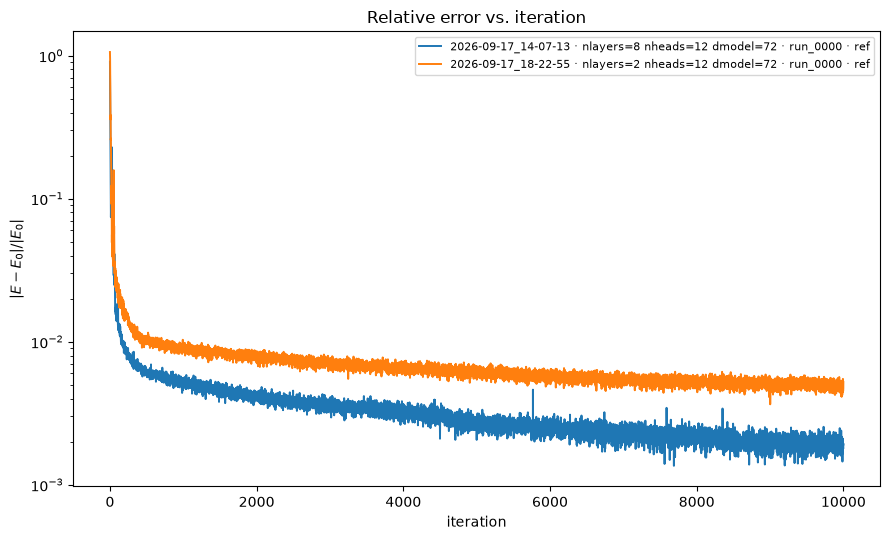

In [84]:
fig, ax = plt.subplots(figsize=(9, 5.5))
plotted = False
for r in runs:
    if r["E0"] is None:
        continue
    rel = np.abs(r["mean"] - r["E0"]) / abs(r["E0"])
    src = "ref" if r["E0_source"] == "ref" else "ED"
    ax.semilogy(r["iters"], rel, lw=1.4,
                label=f"{run_label(r, include_git=False)} · {src}")
    plotted = True

if plotted:
    ax.set_xlabel("iteration")
    ax.set_ylabel(r"$|E - E_0| / |E_0|$")
    ax.set_title("Relative error vs. iteration")
    ax.legend(fontsize=8, loc="best")
    fig.tight_layout()
    plt.show()
else:
    print("No reference E0 available for these runs — nothing to plot.")

## Adaptive alpha vs. iteration

For runs with `auto_alpha = true`, VMC_NG tunes the overdispersion exponent of
the sampling distribution `q ∝ |ψ|^α` every step by ascending the gradient of
the gradient-SNR, and logs the trajectory under `info.alpha`. The dashed line is
the *initial* α from `config.json` — with adaptive tuning that value is only a
starting point, so the gap between it and the plateau is the interesting part.

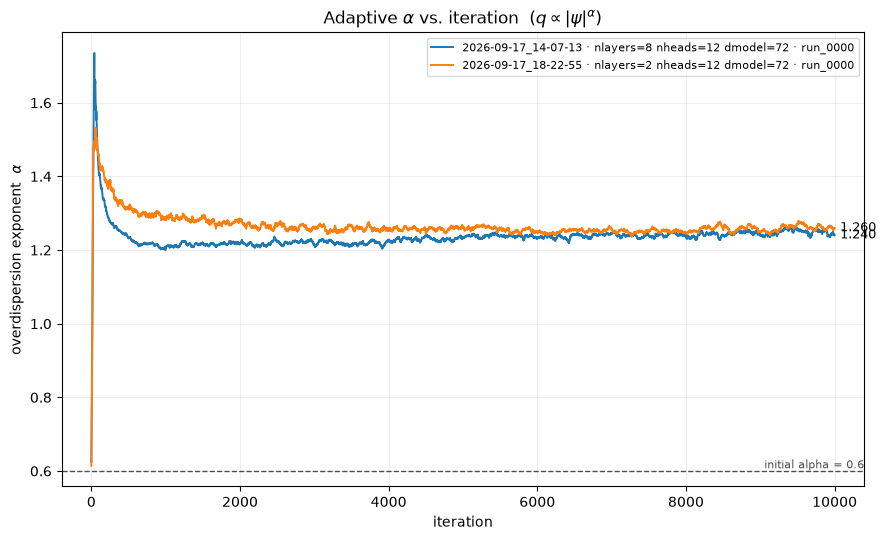

In [85]:
alpha_runs = []
for r in runs:
    loaded = load_run_info(r["run_dir"], "alpha")
    if loaded is not None:
        alpha_runs.append((r, *loaded))

if not alpha_runs:
    print("No run here has an info.alpha series — these are all fixed-alpha runs "
          "(auto_alpha = false, or predating adaptive importance sampling).")
else:
    fig, ax = plt.subplots(figsize=(9, 5.5))
    for r, it, a in alpha_runs:
        ax.plot(it, a, lw=1.4, label=run_label(r, include_git=False))
        # direct-label the endpoint rather than making the reader chase the legend
        ax.annotate(f"{a[-1]:.3f}", xy=(it[-1], a[-1]), xytext=(4, 0),
                    textcoords="offset points", ha="left", va="center", fontsize=9)

    # the configured STARTING exponent(s), for reference against the plateau
    starts = set()
    for r, _, _ in alpha_runs:
        cj = r["run_dir"] / "config.json"
        if cj.exists():
            a0 = json.loads(cj.read_text()).get("distribution", {}).get("alpha")
            if a0 is not None:
                starts.add(float(a0))
    for a0 in sorted(starts):
        ax.axhline(a0, ls="--", color="0.3", lw=1)
        ax.annotate(f"initial alpha = {a0:g}", xy=(1.0, a0),
                    xycoords=("axes fraction", "data"),
                    ha="right", va="bottom", fontsize=8, color="0.3")

    ax.set_xlabel("iteration")
    ax.set_ylabel(r"overdispersion exponent  $\alpha$")
    ax.set_title(r"Adaptive $\alpha$ vs. iteration  ($q \propto |\psi|^{\alpha}$)")
    ax.margins(x=0.04)                      # room for the endpoint labels
    ax.grid(alpha=0.25, lw=0.6)
    ax.set_axisbelow(True)
    if len(alpha_runs) > 1:                 # one curve is named by the title
        ax.legend(fontsize=8, loc="best")
    fig.tight_layout()
    plt.show()

## Peek at a raw log (troubleshooting)

If a plot looks wrong or empty, run this to inspect the actual keys NetKet wrote,
in case your build serializes them differently than `Mean` / `Sigma` / `iters`.

In [86]:
sample = next((r["run_dir"] for r in runs), None)
if sample is None:
    print("No runs loaded yet.")
else:
    logs = sorted(sample.glob("*.log"))
    print("run dir:", sample)
    print("logs   :", [p.name for p in logs])
    if logs:
        blk = json.load(open(logs[0]))
        print("top-level keys:", list(blk))
        if QUANTITY in blk:
            print(f"{QUANTITY!r} sub-keys:", list(blk[QUANTITY]))

run dir: /Users/ashilcusky/Documents/master/2D_data/2026-09-17_14-07-13Gbcd9a5dP2861577/run_0000
logs   : ['run step 1205.log', 'run step 2393.log', 'run step 3596.log', 'run step 4799.log', 'run step 5992.log', 'run step 7191.log', 'run step 8385.log', 'run step 9588.log', 'run.log']
top-level keys: ['Energy', 'info']
'Energy' sub-keys: ['iters', 'Mean', 'Variance', 'Sigma', 'R_hat', 'TauCorr', 'TauCorrMax']
